In [1]:
from tensorflow import keras
from keras.models import Model
from keras import layers
from keras.layers import Dense, Input, BatchNormalization, Activation
from keras.layers import Conv2D, SeparableConv2D, MaxPooling2D, GlobalAveragePooling2D, GlobalMaxPooling2D
#from keras.applications.imagenet_utils import _obtain_input_shape
#from keras.utils.data_utils import get_file
from sklearn.model_selection import KFold
from keras.datasets import mnist
from PIL import Image
# for creating a one hot vector for labels
#from keras.utils import np_utils
from IPython.display import display, Image
#import the models
from keras import Model
#add layers
from keras import layers
#add optimizer
from keras import optimizers
#add loss function 
from keras import losses
import random

import keras
import numpy as np
import pandas as pd 
import os
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import json
from skimage.metrics import structural_similarity as ssim

print("Hello world.")

2026-06-18 15:08:25.697844: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781795305.900374      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781795305.958717      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781795306.460163      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781795306.460225      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781795306.460229      57 computation_placer.cc:177] computation placer alr

Hello world.


In [2]:
import numpy as np
import cv2


import numpy as np
import cv2

def apply_perturbations(images, perturbation):
   

    perturbed_images = []
    p_type = perturbation.get("type")

    for img in images:
        img_copy = img.copy()

        # ---------------- GAUSSIAN BLUR ----------------
        if p_type == 'gaussian_blur':
            k = perturbation.get('kernel_size', 5)
            if k % 2 == 0:
                k += 1
            img_copy = cv2.GaussianBlur(img_copy, (k, k), 0)

        # ---------------- NOISE ----------------
        elif p_type == 'noise':
            mean = perturbation.get('mean', 0)
            std = perturbation.get('std', 0.05)
            noise = np.random.normal(mean, std, img_copy.shape)
            img_copy = np.clip(img_copy + noise, 0, 1)

        # ---------------- BRIGHTNESS ----------------
        elif p_type == 'brightness':
            factor = perturbation.get('factor', 0.2)
            img_copy = np.clip(img_copy + factor, 0, 1)

        # ---------------- HUE SHIFT ----------------
        elif p_type == 'hue_shift':
            hsv = cv2.cvtColor((img_copy * 255).astype(np.uint8), cv2.COLOR_RGB2HSV)
            hsv[..., 0] = (hsv[..., 0] + perturbation.get('shift', 10)) % 180
            img_copy = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB).astype(np.float32) / 255.0

        # ---------------- CONTRAST ----------------
        elif p_type == 'contrast':
            factor = perturbation.get('factor', 1.0)
            mean = np.mean(img_copy, axis=(0, 1), keepdims=True)
            img_copy = np.clip((img_copy - mean) * factor + mean, 0, 1)

        # ---------------- GAMMA ----------------
        elif p_type == 'gamma':
            gamma = max(perturbation.get('gamma', 1.0), 1e-6)
            img_copy = np.clip(img_copy ** gamma, 0, 1)

        # ---------------- MOTION BLUR ----------------
        elif p_type == 'motion_blur':
            k = perturbation.get('kernel_size', 7)
            if k % 2 == 0:
                k += 1

            kernel = np.zeros((k, k))
            kernel[k // 2, :] = np.ones(k)
            kernel = kernel / k

            img_copy = cv2.filter2D(img_copy, -1, kernel)

        # ---------------- COMPRESSION ----------------
        elif p_type == 'compression':
            quality = perturbation.get('quality', 30)

            encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
            img_uint8 = (img_copy * 255).astype(np.uint8)

            _, encimg = cv2.imencode('.jpg', img_uint8, encode_param)
            decimg = cv2.imdecode(encimg, 1)

            img_copy = decimg.astype(np.float32) / 255.0

        # ---------------- OCCLUSION ----------------
        elif p_type == 'occlusion':
            size = perturbation.get('size', 0.2)
            h, w = img_copy.shape[:2]

            occ_h = int(h * size)
            occ_w = int(w * size)

            y = np.random.randint(0, h - occ_h)
            x = np.random.randint(0, w - occ_w)

            img_copy[y:y+occ_h, x:x+occ_w] = 0.0

        # ---------------- ERROR HANDLING ----------------
        else:
            raise ValueError(f"Unsupported perturbation type: {p_type}")

        perturbed_images.append(img_copy)

    return np.array(perturbed_images, dtype=np.float32)

In [3]:
def create_mask_from_json(json_file, img_size):
    # If file does not exist or is empty, return blank mask
    if not os.path.exists(json_file) or os.path.getsize(json_file) == 0:
        print(f"Warning: JSON file missing or empty: {json_file}")
        return np.zeros((img_size, img_size), dtype=np.uint8)

    # read json
    with open(json_file, "r") as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError:
            print(f"Warning: JSON file invalid: {json_file}")
            return np.zeros((img_size, img_size), dtype=np.uint8)

    mask = np.zeros((img_size, img_size), dtype=np.uint8)

    # loop over each shape (polygon)
    for shape in data.get("shapes", []):
        pts = np.array(shape["points"], dtype=np.int32)
        pts = pts.reshape((-1, 1, 2))

        # fill polygon
        cv2.fillPoly(mask, [pts], 255)

    return mask

In [4]:
x = []
label = []
x_validation = []
label_validation = []
x_test = []
image_test= []
label_test = []
mask_test = []
img_size = 224

test_range  = []

In [5]:
image_folder0 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Apple"
csv_file0 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/apple_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Apple"


columns = csv_file0.columns
print(list(columns))

for i in range(0, len(csv_file0)):
    image_name = csv_file0.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file0.loc[i]["used_for"]
    
    image = cv2.imread(image_folder0 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([0])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([0])
    else:
        x.append(image)
        label.append([0])


test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [6]:
image_folder1 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Berry"
csv_file1 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/berry_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Berry"


columns = csv_file1.columns
print(list(columns))

for i in range(0, len(csv_file1)):
    image_name = csv_file1.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file1.loc[i]["used_for"]
    
    image = cv2.imread(image_folder1 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([1])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([1])
    else:
        x.append(image)
        label.append([1])


test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [7]:
image_folder2 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Fig"
csv_file2 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/fig_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Fig"


columns = csv_file2.columns
print(list(columns))

for i in range(0, len(csv_file2)):
    image_name = csv_file2.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file2.loc[i]["used_for"]
    
    image = cv2.imread(image_folder2 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([2])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([2])
    else:
        x.append(image)
        label.append([2])


test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [8]:
image_folder3 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Guava"
csv_file3 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/guava_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Guava"


columns = csv_file3.columns
print(list(columns))

for i in range(0, len(csv_file3)):
    image_name = csv_file3.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file3.loc[i]["used_for"]
    
    image = cv2.imread(image_folder3 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([3])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([3])
    else:
        x.append(image)
        label.append([3])

test_range.append(len(x_test))

print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [9]:
image_folder4 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Orange"
csv_file4 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/orange_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Orange"


columns = csv_file4.columns
print(list(columns))

for i in range(0, len(csv_file4)):
    image_name = csv_file4.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file4.loc[i]["used_for"]
    
    image = cv2.imread(image_folder4 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([4])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([4])
    else:
        x.append(image)
        label.append([4])


test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [10]:
image_folder5 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Palm"
csv_file5 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/palm_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Palm"


columns = csv_file5.columns
print(list(columns))

for i in range(0, len(csv_file5)):
    image_name = csv_file5.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file5.loc[i]["used_for"]
    
    image = cv2.imread(image_folder5 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([5])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([5])
    else:
        x.append(image)
        label.append([5])

test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [11]:
image_folder6 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Persimmon"
csv_file6 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/persimmon_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Persimmon"


columns = csv_file6.columns
print(list(columns))

for i in range(0, len(csv_file6)):
    image_name = csv_file6.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file6.loc[i]["used_for"]
    
    image = cv2.imread(image_folder6 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([6])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([6])
    else:
        x.append(image)
        label.append([6])


test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [12]:
image_folder7 = "/kaggle/input/datasets/mahmoudshaheen1134/plant-leaf-image-dataset/New_data/Tomato"
csv_file7 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/egypli-split/EGYPLI_split/tomato_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/egypli-annotated-json-files/annotated/Tomato"


columns = csv_file7.columns
print(list(columns))

for i in range(0, len(csv_file7)):
    image_name = csv_file7.loc[i]["image"]
    json_name = image_name.replace(".jpg", ".json")
    fold = csv_file7.loc[i]["used_for"]
    
    image = cv2.imread(image_folder7 +'/'+ image_name)
    image_original = image
    #image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0

    json_file = json_folder + '/' +json_name

    if fold == "testing":
        x_test.append(image)
        label_test.append([7])
        mask = create_mask_from_json( json_file , image_original.shape[0])
        #mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([7])
    else:
        x.append(image)
        label.append([7])


test_range.append(len(x_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
Hello world.


In [13]:
x = np.asarray(x)
x_validation = np.asarray(x_validation)
x_test = np.asarray(x_test)

print(len(x)," ", len(x_validation)," ", len(x_test))

2868   359   361


In [14]:
from tensorflow.keras.utils import to_categorical 

label = np.array(label)
label = to_categorical(label , 8 )
print(len(label))



label_validation = np.array(label_validation)
label_validation = to_categorical(label_validation , 8 )
print(len(label_validation))

label_test = np.array(label_test)
label_test = to_categorical(label_test , 8 )
print(len(label_test))

2868
359
361


In [15]:
x_test_blur = apply_perturbations(x_test, {'type':'gaussian_blur','kernel_size':5})
x_test_noise = apply_perturbations(x_test, {'type':'noise','mean':0,'std':0.05})
x_test_brightness = apply_perturbations(x_test, {'type':'brightness','factor':0.2})
x_test_hue = apply_perturbations(x_test, {'type':'hue_shift','shift':15})
x_test_contrast = apply_perturbations(
    x_test,
    {'type': 'contrast', 'factor': 0.5}
)

x_test_gamma = apply_perturbations(
    x_test,
    {'type': 'gamma', 'gamma': 2.0}
)

x_test_motion_blur = apply_perturbations(
    x_test,
    {'type': 'motion_blur', 'kernel_size': 7}
)
# ---------------- COMPRESSION ----------------
x_test_compression = apply_perturbations(
    x_test,
    {'type': 'compression', 'quality': 30}   # lower = stronger compression
)

# ---------------- OCCLUSION ----------------
x_test_occlusion = apply_perturbations(
    x_test,
    {'type': 'occlusion', 'size': 0.2}   # 20% area blocked
)



x_test_blur = np.array(x_test_blur, dtype=np.float32)
x_test_noise = np.array(x_test_noise, dtype=np.float32)
x_test_brightness = np.array(x_test_brightness, dtype=np.float32)
x_test_hue = np.array(x_test_hue, dtype=np.float32)
x_test_contrast = np.array(x_test_contrast , dtype=np.float32)
x_test_gamma = np.array(x_test_gamma , dtype=np.float32)
x_test_motion_blur = np.array(x_test_motion_blur , dtype=np.float32)
x_test_compression = np.array(x_test_compression , dtype=np.float32)
x_test_occlusion = np.array(x_test_occlusion , dtype=np.float32)

print("Hello world.")

Hello world.


In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense


model_path = "/kaggle/input/datasets/ragibmehedi/egypli-keras-files/EGYPLI_keras_files/VGG16_EGYPLI.keras"

model = keras.models.load_model(model_path) 

model.summary()

I0000 00:00:1781795360.386163      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781795360.391925      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,914,778 (56.90 MB)

 Trainable params: 66,696 (260.53 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 133,394 (521.07 KB)

In [17]:
test_loss, test_accuracy = model.evaluate(x_test, label_test )
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

I0000 00:00:1781795364.065536     132 service.cc:152] XLA service 0x7900d8107a40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781795364.065575     132 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781795364.065579     132 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781795364.283160     132 cuda_dnn.cc:529] Loaded cuDNN version 91002


 1/12 ━━━━━━━━━━━━━━━━━━━━ 2:52 16s/step - accuracy: 1.0000 - loss: 0.1006

I0000 00:00:1781795378.967098     132 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


12/12 ━━━━━━━━━━━━━━━━━━━━ 23s 660ms/step - accuracy: 0.9887 - loss: 0.1202
Test Accuracy: 0.9834
Test Loss: 0.1181


In [18]:


test_loss_noise , test_accuracy_noise = model.evaluate(x_test_noise, label_test)
print(f"Test Accuracy noise: {test_accuracy_noise:.4f}")
print(f"Test Loss noise: {test_loss_noise:.4f}")

test_loss_blur , test_accuracy_blur = model.evaluate(x_test_blur, label_test)
print(f"Test Accuracy blur: {test_accuracy_blur:.4f}")
print(f"Test Loss blur: {test_loss_blur:.4f}")


test_loss_brightness , test_accuracy_brightness = model.evaluate(x_test_brightness, label_test)
print(f"Test Accuracy brightness: {test_accuracy_brightness:.4f}")
print(f"Test Loss brightness: {test_loss_brightness:.4f}")

test_loss_hue , test_accuracy_hue = model.evaluate(x_test_hue , label_test)
print(f"Test Accuracy hue: {test_accuracy_hue:.4f}")
print(f"Test Loss hue: {test_loss_hue:.4f}")

test_loss_contrast, test_accuracy_contrast = model.evaluate(x_test_contrast, label_test )
print(f"Test Accuracy contrast: {test_accuracy_contrast:.4f}")
print(f"Test Loss contrast: {test_loss_contrast:.4f}")

test_loss_gamma, test_accuracy_gamma = model.evaluate(x_test_gamma , label_test )
print(f"Test Accuracy gamma: {test_accuracy_gamma:.4f}")
print(f"Test Loss gamma: {test_loss_gamma:.4f}")

test_loss_motion_blur , test_accuracy_motion_blur = model.evaluate(x_test_motion_blur , label_test )
print(f"Test Accuracy blur: {test_accuracy_motion_blur:.4f}")
print(f"Test Loss blur: {test_loss_motion_blur:.4f}")

test_loss_compression, test_accuracy_compression = model.evaluate(x_test_compression, label_test )
print(f"Test Accuracy compression: {test_accuracy_compression:.4f}")
print(f"Test Loss compression: {test_loss_compression:.4f}")

test_loss_occlusion, test_accuracy_occlusion = model.evaluate(x_test_occlusion, label_test )
print(f"Test Accuracy occlusion: {test_accuracy_occlusion:.4f}")
print(f"Test Loss occlusion: {test_loss_occlusion:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - accuracy: 0.9439 - loss: 0.2173
Test Accuracy noise: 0.9501
Test Loss noise: 0.1946
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 179ms/step - accuracy: 0.9085 - loss: 0.3242
Test Accuracy blur: 0.9252
Test Loss blur: 0.2795
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 181ms/step - accuracy: 0.9840 - loss: 0.1532
Test Accuracy brightness: 0.9751
Test Loss brightness: 0.1568
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.9372 - loss: 0.2166
Test Accuracy hue: 0.9474
Test Loss hue: 0.1824
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.7346 - loss: 0.8611
Test Accuracy contrast: 0.7091
Test Loss contrast: 0.9299
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.9617 - loss: 0.1748
Test Accuracy gamma: 0.9529
Test Loss gamma: 0.1959
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 192ms/step - accuracy: 0.6934 - loss: 0.7483
Test Accuracy blur: 0.6953
Test Loss blur: 0.7986
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 193ms/step - accuracy: 0.9696 - loss: 0.2066
Test Accuracy compression: 0

In [19]:

accuracy_stability_noise = 1 - (abs(test_accuracy - test_accuracy_noise))/ (test_accuracy + test_accuracy_noise + 1e-8)
print(f"accuracy_stability_noise : {accuracy_stability_noise }")

accuracy_stability_blur = 1 - (abs(test_accuracy - test_accuracy_blur))/ (test_accuracy + test_accuracy_blur + 1e-8)
print(f"accuracy_stability_blur : {accuracy_stability_blur }")

accuracy_stability_brightness = 1 - (abs(test_accuracy - test_accuracy_brightness))/ (test_accuracy + test_accuracy_brightness + 1e-8)
print(f"accuracy_stability_brightness : {accuracy_stability_brightness }")

accuracy_stability_hue = 1 - (abs(test_accuracy - test_accuracy_hue))/ (test_accuracy + test_accuracy_hue + 1e-8)
print(f"accuracy_stability_hue : {accuracy_stability_hue }")

accuracy_stability_contrast = 1 - (abs(test_accuracy - test_accuracy_contrast))/ (test_accuracy + test_accuracy_contrast + 1e-8)
print(f"accuracy_stability_contrast : {accuracy_stability_contrast }")

accuracy_stability_gamma = 1 - (abs(test_accuracy - test_accuracy_gamma))/ (test_accuracy + test_accuracy_gamma + 1e-8)
print(f"accuracy_stability_gamma : {accuracy_stability_gamma }")

accuracy_stability_motion_blur = 1 - (abs(test_accuracy - test_accuracy_motion_blur))/ (test_accuracy + test_accuracy_motion_blur + 1e-8)
print(f"accuracy_stability_motion_blur : {accuracy_stability_motion_blur }")

accuracy_stability_compression = 1 - (abs(test_accuracy - test_accuracy_compression))/ (test_accuracy + test_accuracy_compression + 1e-8)
print(f"accuracy_stability_compression : {accuracy_stability_compression }")

accuracy_stability_occlusion = 1 - (abs(test_accuracy - test_accuracy_occlusion))/ (test_accuracy + test_accuracy_occlusion + 1e-8)
print(f"accuracy_stability_occlusion : {accuracy_stability_occlusion }")











accuracy_stability_noise : 0.982808034936053
accuracy_stability_blur : 0.9695210424328676
accuracy_stability_brightness : 0.9957567138154313
accuracy_stability_hue : 0.9813486579294538
accuracy_stability_contrast : 0.8379705364445285
accuracy_stability_gamma : 0.9842632363542428
accuracy_stability_motion_blur : 0.8283828516105941
accuracy_stability_compression : 0.9943342815346302
accuracy_stability_occlusion : 0.9481481437028747


In [20]:
for layer in model.layers:
    print( layer.name, layer.output.shape)



input_layer (None, 224, 224, 3)
block1_conv1 (None, 224, 224, 64)
block1_conv2 (None, 224, 224, 64)
block1_pool (None, 112, 112, 64)
block2_conv1 (None, 112, 112, 128)
block2_conv2 (None, 112, 112, 128)
block2_pool (None, 56, 56, 128)
block3_conv1 (None, 56, 56, 256)
block3_conv2 (None, 56, 56, 256)
block3_conv3 (None, 56, 56, 256)
block3_pool (None, 28, 28, 256)
block4_conv1 (None, 28, 28, 512)
block4_conv2 (None, 28, 28, 512)
block4_conv3 (None, 28, 28, 512)
block4_pool (None, 14, 14, 512)
block5_conv1 (None, 14, 14, 512)
block5_conv2 (None, 14, 14, 512)
block5_conv3 (None, 14, 14, 512)
block5_pool (None, 7, 7, 512)
global_average_pooling2d (None, 512)
dropout (None, 512)
dense (None, 128)
dense_1 (None, 8)


In [21]:
last_conv_layer_name = None

for layer in reversed(model.layers):
    if 'conv' in layer.name.lower():
        last_conv_layer_name = layer.name
        break

print(f"Last convolutional layer: {last_conv_layer_name}")

Last convolutional layer: block5_conv3


In [22]:
# ----------------------------
# Grad-CAM heatmap function
# ----------------------------
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]  # (H, W, C)
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), predictions.numpy()[0], int(pred_index)


def binarize_heatmap(heatmap, target_shape, threshold=0.5):
    heatmap_resized = cv2.resize(heatmap, (target_shape[1], target_shape[0]))
    return (heatmap_resized > threshold).astype(np.uint8)

def binarize_mask(mask):
    return (mask > 0).astype(np.uint8)

def LMOS(pred_bin, mask_bin):
    intersection = np.logical_and(pred_bin, mask_bin).sum()
    pred_area = pred_bin.sum()
    return (intersection / pred_area)  if pred_area != 0 else 0.0


overlap_pred_array = []
overlap_pred_noise_array = []
overlap_pred_blur_array = []
overlap_pred_brightness_array = []
overlap_pred_hue_array = []
overlap_pred_contrast_array = []
overlap_pred_gamma_array = []
overlap_pred_motion_blur_array = []
overlap_pred_compression_array = []
overlap_pred_occlusion_array = []

drop_noise = []
drop_blur = []
drop_brightness = []
drop_hue = []
drop_contrast = []
drop_gamma = []
drop_motion_blur = []
drop_compression = []
drop_occlusion = []


for idx in range(len(x_test)):
    # Prepare image for model
    print("idx ", idx)
    img_array = x_test[idx]
    img_array_noise = x_test_noise[idx]
    img_array_brightness = x_test_brightness[idx]
    img_array_blur = x_test_blur[idx]
    img_array_hue = x_test_hue[idx]
    img_array_contrast = x_test_contrast[idx]
    img_array_gamma = x_test_gamma[idx]
    img_array_motion_blur = x_test_motion_blur[idx]
    img_array_compression = x_test_compression[idx]
    img_array_occlusion = x_test_occlusion[idx]
    
    if len(img_array.shape) == 3:
        img_array_exp = np.expand_dims(img_array, axis=0)
        img_array_noise_exp = np.expand_dims(img_array_noise , axis=0)
        img_array_brightness_exp = np.expand_dims(img_array_brightness, axis=0)
        img_array_blur_exp = np.expand_dims(img_array_blur, axis=0)
        img_array_hue_exp = np.expand_dims(img_array_hue, axis=0)
        img_array_contrast_exp = np.expand_dims(img_array_contrast , axis=0)
        img_array_gamma_exp = np.expand_dims(img_array_gamma , axis=0)
        img_array_motion_blur_exp = np.expand_dims(img_array_motion_blur, axis=0)
        img_array_compression_exp = np.expand_dims(img_array_compression , axis=0)
        img_array_occlusion_exp = np.expand_dims(img_array_occlusion, axis=0)

    # True label
    true_label = int(label_test[idx]) if len(np.array(label_test[idx]).shape) == 0 else int(np.argmax(label_test[idx]))

    # Grad-CAM
    heatmap_pred, pred_probs, pred_label = get_gradcam_heatmap(model, img_array_exp, last_conv_layer_name)
    heatmap_pred_noise, pred_probs_noise, pred_label_noise = get_gradcam_heatmap(model, img_array_noise_exp, last_conv_layer_name)
    heatmap_pred_brightness, pred_probs_brightness, pred_label_brightness = get_gradcam_heatmap(model, img_array_brightness_exp, last_conv_layer_name)
    heatmap_pred_blur, pred_probs_blur, pred_label_blur = get_gradcam_heatmap(model, img_array_blur_exp, last_conv_layer_name)
    heatmap_pred_hue, pred_probs_hue, pred_label_hue = get_gradcam_heatmap(model, img_array_hue_exp, last_conv_layer_name)
    heatmap_pred_contrast, pred_probs_contrast, pred_label_contrast = get_gradcam_heatmap(model, img_array_contrast_exp, last_conv_layer_name)
    heatmap_pred_gamma, pred_probs_gamma, pred_label_gamma = get_gradcam_heatmap(model, img_array_gamma_exp, last_conv_layer_name)
    heatmap_pred_motion_blur, pred_probs_motion_blur, pred_label_motion_blur = get_gradcam_heatmap(model, img_array_motion_blur_exp, last_conv_layer_name)
    heatmap_pred_compression, pred_probs_compression, pred_label_compression = get_gradcam_heatmap(model, img_array_compression_exp, last_conv_layer_name)
    heatmap_pred_occlusion, pred_probs_occlusion, pred_label_occlusion = get_gradcam_heatmap(model, img_array_occlusion_exp, last_conv_layer_name)
    
    # Load mask
    mask = mask_test[idx]
    mask_bin = binarize_mask(mask)

    # Binarize Grad-CAM
    pred_bin = binarize_heatmap(heatmap_pred, x_test[idx].shape , threshold=0.7)
    pred_bin_noise = binarize_heatmap(heatmap_pred_noise , x_test[idx].shape , threshold=0.7)
    pred_bin_blur= binarize_heatmap(heatmap_pred_blur, x_test[idx].shape, threshold=0.7)
    pred_bin_brightness = binarize_heatmap(heatmap_pred_brightness, x_test[idx].shape, threshold=0.7)
    pred_bin_hue = binarize_heatmap(heatmap_pred_hue, x_test[idx].shape , threshold=0.7)
    pred_bin_contrast = binarize_heatmap(heatmap_pred_contrast , x_test[idx].shape , threshold=0.7)
    pred_bin_gamma = binarize_heatmap(heatmap_pred_gamma , x_test[idx].shape, threshold=0.7)
    pred_bin_motion_blur = binarize_heatmap(heatmap_pred_motion_blur , x_test[idx].shape, threshold=0.7)
    pred_bin_compression = binarize_heatmap(heatmap_pred_compression , x_test[idx].shape , threshold=0.7)
    pred_bin_occlusion = binarize_heatmap( heatmap_pred_occlusion, x_test[idx].shape, threshold=0.7)

    overlap_pred = LMOS(pred_bin, mask_bin)
    overlap_pred_noise = LMOS(pred_bin_noise, mask_bin)
    overlap_pred_blur = LMOS(pred_bin_blur, mask_bin)
    overlap_pred_brightness = LMOS(pred_bin_brightness, mask_bin )
    overlap_pred_hue = LMOS(pred_bin_hue, mask_bin)
    overlap_pred_contrast = LMOS(pred_bin_contrast, mask_bin)
    overlap_pred_gamma = LMOS(pred_bin_gamma, mask_bin)
    overlap_pred_motion_blur = LMOS(pred_bin_motion_blur, mask_bin)
    overlap_pred_compression = LMOS(pred_bin_compression , mask_bin )
    overlap_pred_occlusion = LMOS(pred_bin_occlusion , mask_bin)

    overlap_pred_array.append(overlap_pred)
    overlap_pred_noise_array.append(overlap_pred_noise)
    overlap_pred_blur_array.append(overlap_pred_blur)
    overlap_pred_brightness_array.append(overlap_pred_brightness)
    overlap_pred_hue_array.append(overlap_pred_hue)
    overlap_pred_contrast_array.append(overlap_pred_contrast)
    overlap_pred_gamma_array.append(overlap_pred_gamma)
    overlap_pred_motion_blur_array.append(overlap_pred_motion_blur)
    overlap_pred_compression_array.append(overlap_pred_compression)
    overlap_pred_occlusion_array.append(overlap_pred_occlusion)


stabilities_noise = []
stabilities_brightness = []
stabilities_blur = []
stabilities_hue = []
stabilities_contrast = []
stabilities_gamma = []
stabilities_motion_blur = []
stabilities_compression = []
stabilities_occlusion = []

for clean, perturbed in zip(overlap_pred_array, overlap_pred_noise_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_noise.append(s)
overlap_pred_stability_noise = np.mean(stabilities_noise)


ERI_noise = np.mean([accuracy_stability_noise , overlap_pred_stability_noise])
print(f"accuracy_stability_noise : {accuracy_stability_noise}")
print(f"overlap_pred_stability_noise : {overlap_pred_stability_noise} ")
print(f"ERI_noise : {ERI_noise}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_blur_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_blur.append(s)
overlap_pred_stability_blur = np.mean(stabilities_blur)


ERI_blur = np.mean([accuracy_stability_blur , overlap_pred_stability_blur])
print(f"accuracy_stability_blur : {accuracy_stability_blur}")
print(f"overlap_pred_stability_blur : {overlap_pred_stability_blur} ")
print(f"ERI_blur : {ERI_blur}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_brightness_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_brightness.append(s)
overlap_pred_stability_brightness = np.mean(stabilities_brightness)


ERI_brightness = np.mean([accuracy_stability_brightness , overlap_pred_stability_brightness])
print(f"accuracy_stability_brightness : {accuracy_stability_brightness} ")
print(f"overlap_pred_stability_brightness : {overlap_pred_stability_brightness} ")
print(f"ERI_brightness : {ERI_brightness}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_hue_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_hue.append(s)
overlap_pred_stability_hue = np.mean(stabilities_hue)


ERI_hue = np.mean([accuracy_stability_hue , overlap_pred_stability_hue])
print(f"accuracy_stability_hue : {accuracy_stability_hue}")
print(f"overlap_pred_stability_hue : {overlap_pred_stability_hue}")
print(f"ERI_hue : {ERI_hue}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_contrast_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_contrast.append(s)
overlap_pred_stability_contrast = np.mean(stabilities_contrast)


ERI_contrast = np.mean([accuracy_stability_contrast , overlap_pred_stability_contrast])
print(f"accuracy_stability_contrast : {accuracy_stability_contrast}")
print(f"overlap_pred_stability_contrast : {overlap_pred_stability_contrast} ")
print(f"ERI_contrast : {ERI_contrast}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_gamma_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_gamma.append(s)
overlap_pred_stability_gamma = np.mean(stabilities_gamma)


ERI_gamma = np.mean([accuracy_stability_gamma , overlap_pred_stability_gamma])
print(f"accuracy_stability_gamma : {accuracy_stability_gamma}")
print(f"overlap_pred_stability_gamma : {overlap_pred_stability_gamma} ")
print(f"ERI_gamma : {ERI_gamma}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_motion_blur_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_motion_blur.append(s)
overlap_pred_stability_motion_blur = np.mean(stabilities_motion_blur)


ERI_motion_blur = np.mean([accuracy_stability_motion_blur , overlap_pred_stability_motion_blur])
print(f"accuracy_stability_motion_blur : {accuracy_stability_motion_blur}")
print(f"overlap_pred_stability_motion_blur : {overlap_pred_stability_motion_blur} ")
print(f"ERI_motion_blur : {ERI_motion_blur}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_compression_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_compression.append(s)
overlap_pred_stability_compression = np.mean(stabilities_compression)


ERI_compression = np.mean([accuracy_stability_compression , overlap_pred_stability_compression])
print(f"accuracy_stability_compression : {accuracy_stability_compression}")
print(f"overlap_pred_stability_compression : {overlap_pred_stability_compression}  ")
print(f"ERI_compression : {ERI_compression}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_occlusion_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_occlusion.append(s)
overlap_pred_stability_occlusion = np.mean(stabilities_occlusion)


ERI_occlusion = np.mean([accuracy_stability_occlusion , overlap_pred_stability_occlusion])
print(f"accuracy_stability_occlusion : {accuracy_stability_occlusion}")
print(f"overlap_pred_stability_occlusion : {overlap_pred_stability_occlusion} ")
print(f"ERI_occlusion : {ERI_occlusion}")

idx  0


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


idx  1
idx  2
idx  3
idx  4
idx  5
idx  6
idx  7
idx  8
idx  9
idx  10
idx  11
idx  12
idx  13
idx  14
idx  15
idx  16
idx  17
idx  18
idx  19
idx  20
idx  21
idx  22
idx  23
idx  24
idx  25
idx  26
idx  27
idx  28
idx  29
idx  30
idx  31
idx  32
idx  33
idx  34
idx  35
idx  36
idx  37
idx  38
idx  39
idx  40
idx  41
idx  42
idx  43
idx  44
idx  45
idx  46
idx  47
idx  48
idx  49
idx  50
idx  51
idx  52
idx  53
idx  54
idx  55
idx  56
idx  57
idx  58
idx  59
idx  60
idx  61
idx  62
idx  63
idx  64
idx  65
idx  66
idx  67
idx  68
idx  69
idx  70
idx  71
idx  72
idx  73
idx  74
idx  75
idx  76
idx  77
idx  78
idx  79
idx  80
idx  81
idx  82
idx  83
idx  84
idx  85
idx  86
idx  87
idx  88
idx  89
idx  90
idx  91
idx  92
idx  93
idx  94
idx  95
idx  96
idx  97
idx  98
idx  99
idx  100
idx  101
idx  102
idx  103
idx  104
idx  105
idx  106
idx  107
idx  108
idx  109
idx  110
idx  111
idx  112
idx  113
idx  114
idx  115
idx  116
idx  117
idx  118
idx  119
idx  120
idx  121
idx  122
idx  123
i


================ ERI ABLATION STUDY TABLE ================

Perturbation  Accuracy_Stability  LMOS_Stability  ERI_Full  ERI_No_Accuracy  ERI_No_LMOS
       Noise            0.982808        0.757638  0.870223         0.378819     0.491404
        Blur            0.969521        0.701438  0.835479         0.350719     0.484761
  Brightness            0.995757        0.881236  0.938496         0.440618     0.497878
         Hue            0.981349        0.783559  0.882454         0.391780     0.490674
    Contrast            0.837971        0.536224  0.687097         0.268112     0.418985
       Gamma            0.984263        0.743248  0.863755         0.371624     0.492132
 Motion Blur            0.828383        0.500670  0.664526         0.250335     0.414191
 Compression            0.994334        0.769293  0.881814         0.384646     0.497167
   Occlusion            0.948148        0.656396  0.802272         0.328198     0.474074

================ SUMMARY ================

Mean 

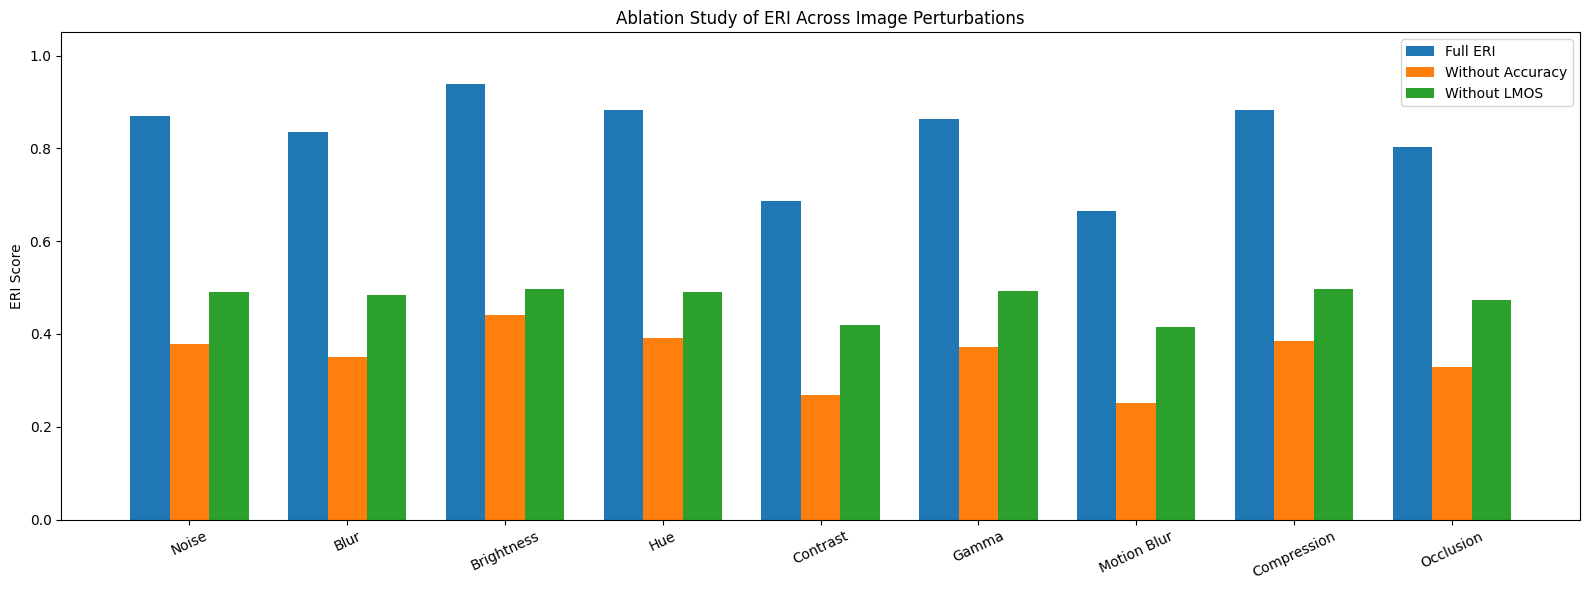

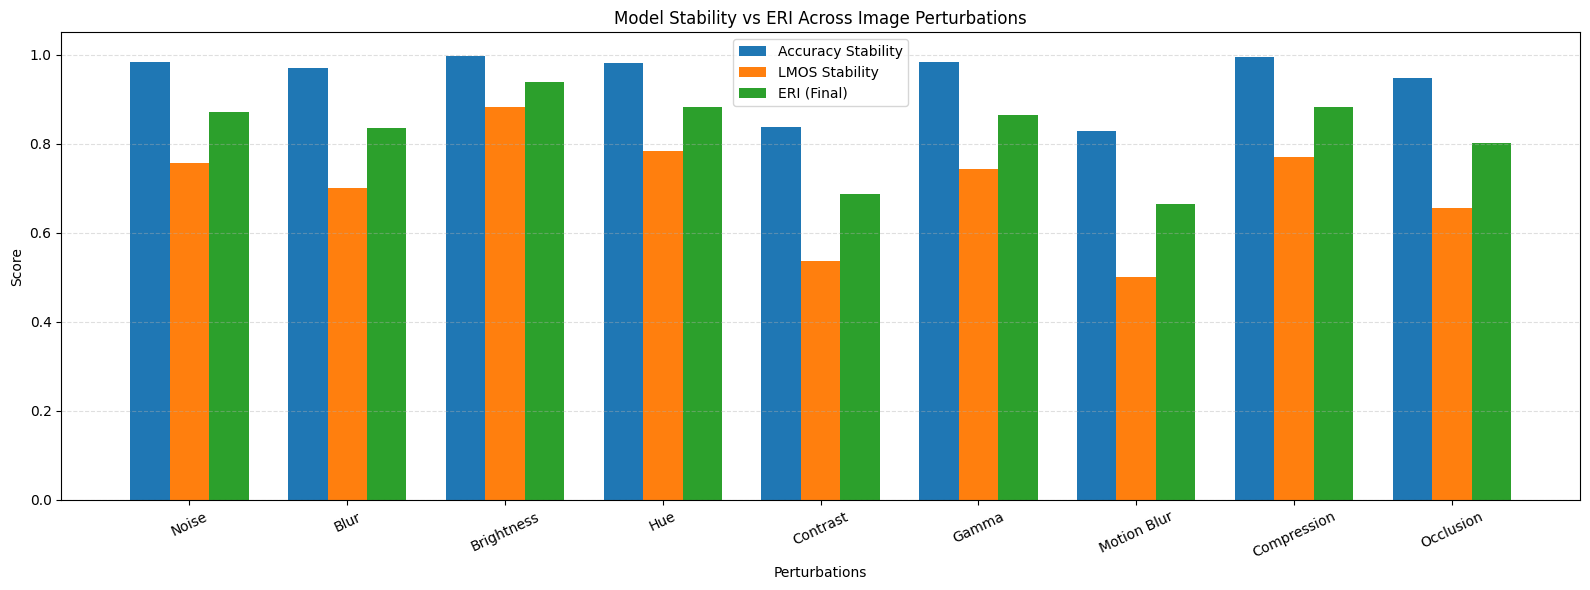

Saved: eri_components_bar.png


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================================================
# PERTURBATIONS
# ====================================================

perturbations = [
    "Noise", "Blur", "Brightness", "Hue",
    "Contrast", "Gamma", "Motion Blur",
    "Compression", "Occlusion"
]

# ====================================================
# YOUR VALUES (already computed in your code)
# ====================================================

acc_stab = [
    accuracy_stability_noise,
    accuracy_stability_blur,
    accuracy_stability_brightness,
    accuracy_stability_hue,
    accuracy_stability_contrast,
    accuracy_stability_gamma,
    accuracy_stability_motion_blur,
    accuracy_stability_compression,
    accuracy_stability_occlusion
]

lmos_stab = [
    overlap_pred_stability_noise,
    overlap_pred_stability_blur,
    overlap_pred_stability_brightness,
    overlap_pred_stability_hue,
    overlap_pred_stability_contrast,
    overlap_pred_stability_gamma,
    overlap_pred_stability_motion_blur,
    overlap_pred_stability_compression,
    overlap_pred_stability_occlusion
]

# ====================================================
# ERI COMPUTATION
# ====================================================

eri_full = [(a + l) / 2 for a, l in zip(acc_stab, lmos_stab)]
eri_no_acc = [l / 2 for l in lmos_stab]
eri_no_lmos = [a / 2 for a in acc_stab]

# ====================================================
# PRINT TABLE (IMPORTANT FOR PAPER)
# ====================================================

# ====================================================
# PRINT TABLE (IMPORTANT FOR PAPER)
# ====================================================

df = pd.DataFrame({
    "Perturbation": perturbations,
    "Accuracy_Stability": acc_stab,
    "LMOS_Stability": lmos_stab,
    "ERI_Full": eri_full,
    "ERI_No_Accuracy": eri_no_acc,
    "ERI_No_LMOS": eri_no_lmos
})

# ====================================================
# MEAN VALUES (ADDED)
# ====================================================

mean_accuracy = np.mean(acc_stab)
mean_lmos = np.mean(lmos_stab)
mean_eri = np.mean(eri_full)

print("\n================ ERI ABLATION STUDY TABLE ================\n")
print(df.to_string(index=False))

print("\n================ SUMMARY ================\n")
print(f"Mean Accuracy Stability : {mean_accuracy:.6f}")
print(f"Mean LMOS Stability     : {mean_lmos:.6f}")
print(f"Mean ERI (Full)         : {mean_eri:.6f}")
print(f"Mean ERI (No Accuracy)   : {np.mean(eri_no_acc):.6f}")
print(f"Mean ERI (No LMOS)       : {np.mean(eri_no_lmos):.6f}")
# ====================================================
# PLOT (PUBLICATION STYLE)
# ====================================================

x = np.arange(len(perturbations))
width = 0.25

plt.figure(figsize=(16,6))

bars1 = plt.bar(x - width, eri_full, width, label="Full ERI")
bars2 = plt.bar(x, eri_no_acc, width, label="Without Accuracy")
bars3 = plt.bar(x + width, eri_no_lmos, width, label="Without LMOS")

plt.xticks(x, perturbations, rotation=25)
plt.ylabel("ERI Score")
plt.title("Ablation Study of ERI Across Image Perturbations")
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.savefig("eri_ablation_study_per_perturbation_xception.png", dpi=300, bbox_inches='tight')
plt.show()



# ====================================================
# SECOND FIGURE: BAR CHART (BETTER FOR PAPER)
# ====================================================

plt.figure(figsize=(16,6))

x = np.arange(len(perturbations))
width = 0.25

plt.bar(x - width, acc_stab, width, label="Accuracy Stability")
plt.bar(x, lmos_stab, width, label="LMOS Stability")
plt.bar(x + width, eri_full, width, label="ERI (Final)")

plt.xticks(x, perturbations, rotation=25)
plt.ylabel("Score")
plt.xlabel("Perturbations")
plt.title("Model Stability vs ERI Across Image Perturbations")

plt.ylim(0, 1.05)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig(
    "eri_components_bar.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print("Saved: eri_components_bar.png")